<a href="https://colab.research.google.com/github/SethSekyere/ML-engineering-portfolio/blob/main/projects/02-FlowerFlow/FlowerFlow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**FlowerFlow — Robust Computer Vision Data Pipelines with PyTorch**

A data engineering project focused on preparing, transforming, batching, and validating image data for deep learning workflows.

***Project Objectives***

This project focuses on building a robust and reusable image data pipeline with PyTorch.

Explore a real-world image dataset with unorganized files and separate labels.

Implement a custom PyTorch Dataset to load and preprocess images and labels on demand.

Apply image transformations and data augmentation to improve data consistency and support model generalization.

Configure PyTorch DataLoader instances for efficient batching and data shuffling.

Organize the dataset into training, validation, and test sets.

Implement error handling and performance monitoring to improve the reliability of the data pipeline.

## Imports

In [1]:

# ============================================================
# 1. Repository Setup
# ============================================================

from pathlib import Path
import sys

# GitHub repository containing the portfolio projects.
REPO_URL = "https://github.com/SethSekyere/ML-engineering-portfolio.git"

# Local path for the repository in Google Colab.
REPO_DIR = Path("/content/ML-engineering-portfolio")

# Clone the repository or update an existing clone.
if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    print("Repository already exists. Updating...")
    !git -C {REPO_DIR} pull

# Set the path to the FlowerFlow project.
PROJECT_DIR = REPO_DIR / "projects" / "02-FlowerFlow"

# Set the path to the dependency file.
REQUIREMENTS_FILE = PROJECT_DIR / "requirements.txt"

# Add the project directory to Python's import path.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Verify that required project files exist.
assert (PROJECT_DIR / "helper_utils.py").exists(), (
    f"helper_utils.py not found at {PROJECT_DIR}"
)
assert REQUIREMENTS_FILE.exists(), (
    f"requirements.txt not found at {REQUIREMENTS_FILE}"
)

print(f"Repository: {REPO_DIR}")
print(f"Project: {PROJECT_DIR}")
print("Project files verified.")


Repository already exists. Updating...
Already up to date.
Repository: /content/ML-engineering-portfolio
Project: /content/ML-engineering-portfolio/projects/02-FlowerFlow
Project files verified.


In [2]:
# ============================================================
# 2. Install Project Dependencies
# ============================================================

%pip install -r /content/ML-engineering-portfolio/projects/02-FlowerFlow/requirements.txt

In [3]:

# --- Standard library ---
import os
import tarfile

# --- Data handling and visualization ---
import numpy as np
import matplotlib.pyplot as plt
import scipy

# --- Downloading and processing images ---
import requests
from PIL import Image

# --- PyTorch data pipeline ---
from torch.utils.data import Dataset, Subset, random_split, DataLoader
from torchvision import transforms

# --- Progress monitoring ---
from tqdm.auto import tqdm

# --- Project utilities ---
import helper_utils


## Data Access and Exploration

Reliable data access is the foundation of a reproducible machine learning pipeline. Real-world datasets may be distributed across multiple files or stored in formats that require preprocessing before they can be used for model training.

### Dataset Preparation

The first step is to download the dataset, extract its contents, and inspect its structure to understand how the images and labels are stored.

This project uses a `download_dataset` function to automate data retrieval and extraction:

- Download the dataset files from their specified URLs using `requests`.
- Extract the compressed image archive (`.tgz`) using `tarfile`.
- Retrieve the accompanying `.mat` file containing the image labels.

Separating data retrieval from subsequent preprocessing makes the pipeline easier to organize, reproduce, and maintain.

In [4]:

def download_dataset():
    """
    Download and extract the Oxford 102 Flowers dataset if it is not
    already available locally.

    The function retrieves the image archive and MATLAB label file,
    extracts the images, and saves a text file containing the class names.
    """
    # Keep the dataset files together in one directory.
    data_dir = "flower_data"

    # Define the paths used to check whether the dataset is already available.
    image_folder_path = os.path.join(data_dir, "jpg")
    labels_file_path = os.path.join(data_dir, "imagelabels.mat")
    tgz_path = os.path.join(data_dir, "102flowers.tgz")

    # Skip downloading if the images and label file are already present.
    if os.path.exists(image_folder_path) and os.path.exists(labels_file_path):
        print(f"Dataset already exists. Loading locally from '{data_dir}'.")
        return

    # Source URLs for the flower images and their corresponding labels.
    image_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
    labels_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat"

    # Create the data directory if this is the first time running the pipeline.
    os.makedirs(data_dir, exist_ok=True)

    # Download the image archive in chunks to avoid loading the entire file
    # into memory at once.
    print("Downloading images...")
    with requests.get(image_url, stream=True, timeout=60) as response:
        response.raise_for_status()

        # Use the server's file size to estimate the download progress.
        total_size = int(response.headers.get("content-length", 0))
        chunk_size = 1024 * 1024  # Download in 1 MB chunks.

        with open(tgz_path, "wb") as file:
            for chunk in tqdm(
                response.iter_content(chunk_size=chunk_size),
                total=(total_size + chunk_size - 1) // chunk_size
                if total_size else None,
                unit="chunk",
                desc="Downloading images",
            ):
                if chunk:
                    file.write(chunk)

    # Extract the images so they can be accessed individually by the Dataset.
    print("Extracting images...")
    with tarfile.open(tgz_path, "r:gz") as tar:
        tar.extractall(data_dir, filter="data")

    # Download the MATLAB file containing the image labels.
    print("Downloading labels...")
    with requests.get(labels_url, timeout=60) as response:
        response.raise_for_status()

        with open(labels_file_path, "wb") as file:
            file.write(response.content)

    # Map the dataset's 102 classes to their corresponding flower names.
    labels_description = [
        'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells',
        'sweet pea', 'english marigold', 'tiger lily', 'moon orchid',
        'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon',
        "colt's foot", 'king protea', 'spear thistle', 'yellow iris',
        'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower',
        'giant white arum lily', 'fire lily', 'pincushion flower',
        'fritillary', 'red ginger', 'grape hyacinth', 'corn poppy',
        'prince of wales feathers', 'stemless gentian', 'artichoke',
        'sweet william', 'carnation', 'garden phlox', 'love in the mist',
        'mexican aster', 'alpine sea holly', 'ruby-lipped cattleya',
        'cape flower', 'great masterwort', 'siam tulip', 'lenten rose',
        'barbeton daisy', 'daffodil', 'sword lily', 'poinsettia',
        'bolero deep blue', 'wallflower', 'marigold', 'buttercup',
        'oxeye daisy', 'common dandelion', 'petunia', 'wild pansy',
        'primula', 'sunflower', 'pelargonium', 'bishop of llandaff',
        'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia?',
        'cautleya spicata', 'japanese anemone', 'black-eyed susan',
        'silverbush', 'californian poppy', 'osteospermum', 'spring crocus',
        'bearded iris', 'windflower', 'tree poppy', 'gazania', 'azalea',
        'water lily', 'rose', 'thorn apple', 'morning glory',
        'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani',
        'clematis', 'hibiscus', 'columbine', 'desert-rose', 'tree mallow',
        'magnolia', 'cyclamen ', 'watercress', 'canna lily', 'hippeastrum ',
        'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia',
        'mallow', 'mexican petunia', 'bromelia', 'blanket flower',
        'trumpet creeper', 'blackberry lily'
    ]

    # Save one class name per line for convenient lookup during exploration.
    description_path = os.path.join(data_dir, "labels_description.txt")
    with open(description_path, "w", encoding="utf-8") as file:
        file.write("\n".join(labels_description) + "\n")

    print(f"Dataset downloaded and prepared in '{data_dir}'.")


In [5]:
# Call the function to download and prepare the dataset.
download_dataset()

Dataset already exists. Loading locally from 'flower_data'.


In [6]:

# Set the root directory containing the downloaded flower dataset.
path_dataset = "./flower_data"

# Inspect the directory structure to verify where the images,
# labels, and other dataset files are stored.
helper_utils.print_data_folder_structure(
    path_dataset,
    max_depth=1
)


flower_data/
├── 102flowers.tgz
├── imagelabels.mat
├── jpg/
└── labels_description.txt


### Dataset Structure

The dataset contains three key components:

- **`jpg/`** — stores the flower images in JPEG format.
- **`imagelabels.mat`** — contains the image labels in MATLAB format.
- **`labels_description.txt`** — maps the dataset's class indices to flower names.

Understanding this structure helps establish how images and labels will be accessed, matched, and prepared for the PyTorch data pipeline.

### Creating a Custom Dataset Class

To make the flower images and their labels accessible to the training pipeline, I'll implement a custom `FlowerDataset` class based on PyTorch's `torch.utils.data.Dataset`.

The class will handle label loading, image retrieval, and optional transformations while loading images **on demand** rather than storing the entire dataset in memory.

#### Core Methods

- **`__init__`** — Initializes the dataset, sets the data paths, loads the labels, and configures any optional transformations.
- **`__len__`** — Returns the total number of samples available in the dataset.
- **`__getitem__`** — Retrieves an image and its corresponding label by index, applies the configured transformations, and returns the sample.

#### Helper Methods

- **`load_and_correct_labels`** — Uses `scipy.io.loadmat` to load labels from `imagelabels.mat`. Since MATLAB uses 1-based indexing while Python uses 0-based indexing, the labels are adjusted by subtracting one.
- **`retrieve_image`** — Builds the image path from the supplied index, opens the image using Pillow, and converts it to RGB to maintain a consistent image format.
- **`get_label_description`** — Retrieves the human-readable flower name associated with a given label from `labels_description.txt`.

#### Lazy Loading

Images are loaded only when requested through `__getitem__`, rather than all at once during initialization. This approach reduces memory usage and makes the dataset more practical to work with as the number or size of images increases.

In [7]:

class FlowerDataset(Dataset):
    """
    Custom PyTorch dataset for loading flower images and their labels.

    Images are loaded on demand, keeping memory usage low while allowing
    DataLoader to retrieve samples during training and evaluation.
    """

    def __init__(self, root_dir, transform=None):
        """
        Set up the dataset paths, labels, and optional image transforms.

        Args:
            root_dir (str): Root directory containing images and labels.
            transform (callable, optional): Image preprocessing or
                augmentation pipeline applied when a sample is retrieved.
        """
        # Store the dataset location and optional image transformations.
        self.root_dir = root_dir
        self.transform = transform

        # Images are stored separately from the label metadata.
        self.image_dir = os.path.join(self.root_dir, "jpg")

        # Load labels once during initialization instead of reading the
        # MATLAB file every time an image is requested.
        self.labels = self.load_and_correct_labels()

    def __len__(self):
        """Return the number of labeled images in the dataset."""
        return len(self.labels)

    def __getitem__(self, idx):
        """
        Retrieve an image and its corresponding label by index.

        The image is loaded from disk and transformed if a transform
        pipeline was provided.
        """
        # Load only the requested image rather than the entire dataset.
        image = self.retrieve_image(idx)

        # Apply preprocessing or augmentation before returning the image.
        if self.transform is not None:
            image = self.transform(image)

        # Retrieve the label aligned with this image's dataset index.
        label = int(self.labels[idx])

        return image, label

    def retrieve_image(self, idx):
        """
        Load one image from disk and convert it to RGB.

        The filename convention uses five-digit, one-based image numbering.
        """
        # Dataset filenames start at image_00001.jpg, while Python indices
        # start at zero, so add one when constructing the filename.
        img_name = f"image_{idx + 1:05d}.jpg"
        img_path = os.path.join(self.image_dir, img_name)

        # Convert images to RGB so every sample has a consistent color format.
        # The context manager ensures the file is closed after loading.
        with Image.open(img_path) as img:
            image = img.convert("RGB")

        return image

    def load_and_correct_labels(self):
        """
        Load image labels from the MATLAB file and convert them to
        zero-based indices for Python.
        """
        labels_path = os.path.join(self.root_dir, "imagelabels.mat")

        # scipy.io.loadmat reads the labels stored in MATLAB format.
        self.labels_mat = scipy.io.loadmat(labels_path)

        # MATLAB labels start at 1; Python class indices start at 0.
        labels = self.labels_mat["labels"][0] - 1

        return labels

    def get_label_description(self, label):
        """
        Return the flower name associated with a zero-based class label.
        """
        description_path = os.path.join(
            self.root_dir, "labels_description.txt"
        )

        # Read the class names and select the entry matching the label.
        with open(description_path, "r", encoding="utf-8") as file:
            descriptions = file.readlines()

        return descriptions[label].strip()


In [8]:
# Initialize the dataset object, providing the path to the data.
dataset = FlowerDataset(path_dataset)

### Validating the Custom Dataset

Before integrating `FlowerDataset` into the training pipeline, I'll verify that it loads the dataset correctly.

- **Check the dataset size** using `len()` to confirm the total number of labeled samples available.

In [9]:
# Print the total number of samples in the dataset.
print(f'Number of samples in the dataset: {len(dataset)}')

Number of samples in the dataset: 8189


<br>

* Retrieve a specific sample using an index.

In [10]:
# Define an index for a sample to retrieve.
sel_idx = 10

# Retrieve the image and label for the selected index.
img, label = dataset[sel_idx]

- Inspect the image size and label.

In [11]:
# Create a string detailing the image's dimensions.
img_size_info = f"Image size: {img.size}"

# Print the image size information along with its corresponding label.
print(f'{img_size_info}, Label: {label}')

Image size: (500, 748), Label: 76


<br>

* Visualize the image using the helper function `plot_img`.

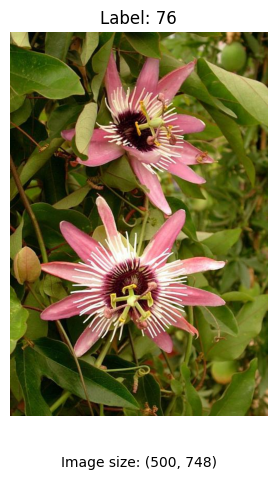

In [12]:
helper_utils.plot_img(img, label=label, info=img_size_info)

### Inspecting the Dataset Labels

Next, I'll inspect the unique labels in the dataset and use `get_label_description()` to display the corresponding flower name for each label.

This helps verify that the labels are loaded correctly and mapped to the expected flower classes.

In [13]:
# Get the labels loaded by the dataset.
dataset_labels = dataset.labels

# Identify the unique flower classes.
unique_labels = set(dataset_labels)

# Print each class label and its corresponding flower name.
for label in unique_labels:
    description = dataset.get_label_description(int(label))
    print(f"Label: {label}, Description: {description}")

Label: 0, Description: pink primrose
Label: 1, Description: hard-leaved pocket orchid
Label: 2, Description: canterbury bells
Label: 3, Description: sweet pea
Label: 4, Description: english marigold
Label: 5, Description: tiger lily
Label: 6, Description: moon orchid
Label: 7, Description: bird of paradise
Label: 8, Description: monkshood
Label: 9, Description: globe thistle
Label: 10, Description: snapdragon
Label: 11, Description: colt's foot
Label: 12, Description: king protea
Label: 13, Description: spear thistle
Label: 14, Description: yellow iris
Label: 15, Description: globe-flower
Label: 16, Description: purple coneflower
Label: 17, Description: peruvian lily
Label: 18, Description: balloon flower
Label: 19, Description: giant white arum lily
Label: 20, Description: fire lily
Label: 21, Description: pincushion flower
Label: 22, Description: fritillary
Label: 23, Description: red ginger
Label: 24, Description: grape hyacinth
Label: 25, Description: corn poppy
Label: 26, Descript

### Visualizing the Dataset

With the custom dataset class in place, I'll inspect a sample of the flower images to get a better understanding of the data.

I'll use the `visual_exploration` function to visualize a few samples and check how the images appear before applying further preprocessing and transformations.

In [14]:
def visual_exploration(dataset, num_rows=2, num_cols=4):
    """
    Display randomly selected dataset samples for visual inspection.

    Args:
        dataset (Dataset): Dataset containing images and labels, with a
            get_label_description method.
        num_rows (int): Number of rows in the image grid.
        num_cols (int): Number of columns in the image grid.
    """
    # Calculate how many samples to display.
    total_samples = num_rows * num_cols

    # Select random dataset indices without replacement.
    indices = np.random.choice(len(dataset), total_samples, replace=False)

    # Set up the grid for displaying the images.
    fig, axes = helper_utils.get_grid(
        num_rows, num_cols, figsize=(num_cols * 3, num_rows * 4)
    )

    # Load each sample and display its image, label, and metadata.
    for ax, idx in zip(axes.flatten(), indices):
        image, label = dataset[idx]

        # Look up the flower name for the current label.
        description = dataset.get_label_description(label)
        label_text = f"{label} - {description}"

        # Include the dataset index and image dimensions.
        info = f"Index: {idx} | Size: {image.size}"

        helper_utils.plot_img(
            image, label=label_text, info=info, ax=ax
        )

    # Display the completed image grid.
    plt.show()

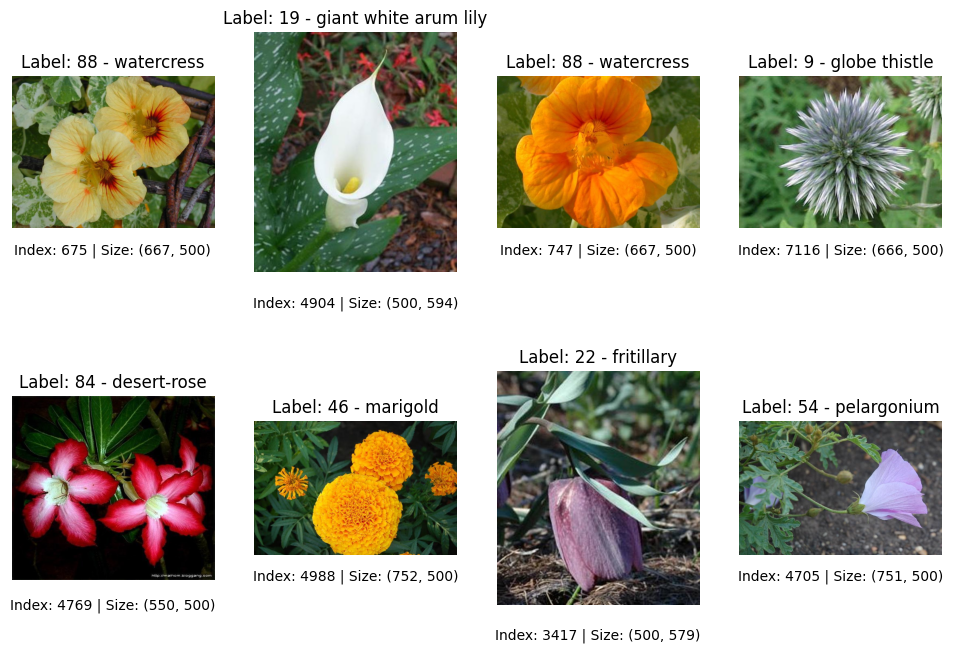

In [15]:
# Display a 2x4 grid of random samples from the dataset for visual inspection.
visual_exploration(dataset, num_rows=2, num_cols=4)

## Image Quality and Preprocessing

As observed during the initial exploration, the images vary in size. Standardizing their dimensions helps ensure that images can be processed in consistent batches by a PyTorch model.

### Applying Image Transformations

I'll use `torchvision.transforms` to define a preprocessing pipeline that standardizes image dimensions and pixel values before the images enter the data pipeline.

The pipeline consists of two stages:

**1. Resize and crop the images**
- `Resize((256, 256))` — Resizes each image to 256 × 256 pixels.
- `CenterCrop(224)` — Crops the center of each image to 224 × 224 pixels.

**2. Convert and normalize the images**
- `ToTensor()` — Converts each PIL image into a PyTorch tensor and scales pixel values from the range [0, 255] to [0, 1].
- `Normalize(mean, std)` — Normalizes each channel using the specified mean and standard deviation.

**Transformation order matters:** resizing and cropping are applied while the image is still in PIL format, before converting it to a tensor and normalizing its pixel values.

In [16]:
# Set the channel-wise mean and standard deviation for normalization.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [17]:
# Define the preprocessing pipeline for the flower images.
transform = transforms.Compose([
    # Standardize image dimensions.
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),

    # Convert images to tensors with pixel values scaled to [0, 1].
    transforms.ToTensor(),

    # Normalize each color channel using the defined mean and standard deviation.
    transforms.Normalize(mean=mean, std=std),
])

Let us now create a new instance of the `FlowerDataset` class, this time passing the transformation pipeline `transform` as an argument.

In [18]:
# Create a dataset instance with the preprocessing pipeline applied to each image.
dataset_transformed = FlowerDataset(
    root_dir=path_dataset,
    transform=transform
)

Now we Inspect the same sample again to see the effect of the transformations. Using `quick_debug`, we can see that the image has been resized and cropped to 224x224 pixels, and its pixel values have been normalized.

Shape: torch.Size([3, 224, 224])
Type: torch.float32
Range of pixel values: [-2.1, 2.6]


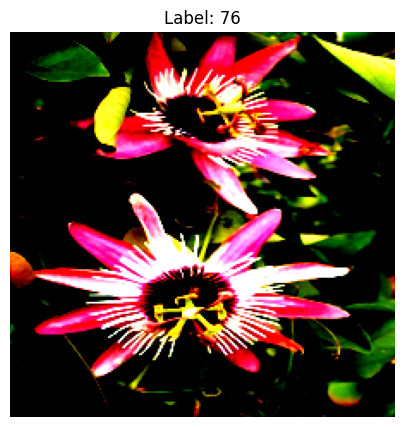

In [19]:
# Retrieve a sample image after applying the transformation pipeline.
img_transformed, label = dataset_transformed[sel_idx]

# Inspect the transformed tensor.
helper_utils.quick_debug(img_transformed)

# Visualize the transformed image and its label.
helper_utils.plot_img(img_transformed, label=label)

The transformed image is now a tensor with shape `[3, 224, 224]`, representing three RGB color channels and a spatial resolution of 224 × 224 pixels.

After normalization, the pixel values no longer fall within the original `[0, 1]` range produced by `ToTensor()`. This is why the image may look different when visualized directly.

To display the image correctly, I'll **denormalize** it by reversing the normalization process using the `new_mean` and `new_std` values. This restores the pixel values to their pre-normalization scale for visualization.

In [20]:
class Denormalize:
    """Reverse channel-wise normalization for image tensors."""

    def __init__(self, mean, std):
        # Calculate the parameters needed to reverse normalization.
        new_mean = [-m / s for m, s in zip(mean, std)]
        new_std = [1 / s for s in std]

        # Use Normalize to apply the inverse transformation.
        self.denormalize = transforms.Normalize(
            mean=new_mean,
            std=new_std
        )

    def __call__(self, tensor):
        """Return the image tensor to its pre-normalized scale."""
        return self.denormalize(tensor)

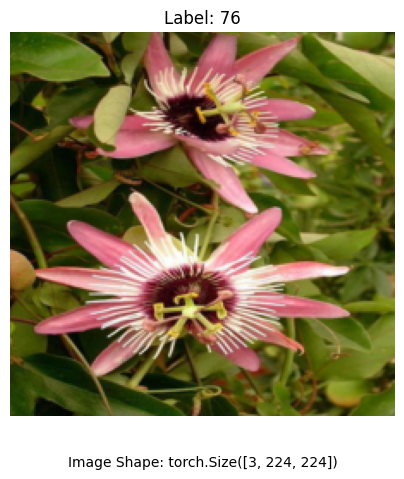

In [21]:
# Set up the denormalization transform using the original mean and std.
denormalize = Denormalize(mean=mean, std=std)

# Reverse normalization to prepare the image for visualization.
img_tensor = denormalize(img_transformed)

# Record the tensor shape for inspection.
img_shape_info = f"Image Shape: {img_tensor.shape}"

# Display the denormalized image with its label and dimensions.
helper_utils.plot_img(
    img_tensor,
    label=label,
    info=img_shape_info
)

## Data Loading

A reliable data pipeline needs to organize samples into separate subsets and deliver them efficiently during model development.

The dataset will be divided into three subsets:

- **Training set** — Used to train the model and update its weights.
- **Validation set** — Used to monitor performance during training and guide model selection and hyperparameter tuning.
- **Test set** — Used to evaluate the final model on data it has not seen during training.

PyTorch's `DataLoader` will then make it easier to retrieve samples in batches, shuffle the training data, and manage data loading.

### Splitting the Dataset

I'll implement a `split_dataset` function to divide the dataset into training, validation, and test subsets.

The function will:
- Calculate the size of each subset using the specified validation and test fractions.
- Assign the remaining samples to the training set.
- Use PyTorch's `random_split` to create the three subsets.

This provides a clear separation between training, validation, and testing data for the downstream machine learning workflow.

In [22]:
def split_dataset(dataset, val_fraction=0.15, test_fraction=0.15):
    """
    Splits a dataset into training, validation, and test sets.

    By default, this function partitions the data into 70% for training,
    15% for validation, and 15% for testing.

    Args:
        dataset (torch.utils.data.Dataset): The complete dataset to be split.
        val_fraction (float): The proportion of the dataset to reserve for validation.
        test_fraction (float): The proportion of the dataset to reserve for testing.

    Returns:
        train_dataset (torch.utils.data.Subset): The dataset split allocated for training.
        val_dataset (torch.utils.data.Subset): The dataset split allocated for validation.
        test_dataset (torch.utils.data.Subset): The dataset split allocated for testing.
    """

    # Calculate the total number of items in the dataset.
    total_size = len(dataset)

    # Calculate the number of items for the validation set.
    val_size = int(total_size * val_fraction)

    # Calculate the number of items for the test set.
    test_size = int(total_size * test_fraction)

    # Calculate the remaining number of items for the training set.
    train_size = total_size - val_size - test_size

    # Partition the dataset into the calculated sizes.
    train_dataset, val_dataset, test_dataset = random_split(
        dataset, [train_size, val_size, test_size]
    )

    # Return the resulting dataset partitions.
    return train_dataset, val_dataset, test_dataset

### Applying Transforms to Dataset Subsets

PyTorch's `random_split` returns `Subset` objects that reference the original dataset. Since each subset uses the original dataset's `__getitem__` method, it also inherits the dataset's existing transformations.

To apply different transformations to each subset without accidentally applying them twice, I'll use the following approach:

1. **Split the raw dataset** without transformations so that each subset returns the original PIL images and their labels.
2. **Wrap each subset** with `SubsetWithTransform`, a lightweight wrapper that applies the specified transformations whenever a sample is retrieved.

This approach allows the training, validation, and test subsets to use their own transformation pipelines while keeping the underlying dataset unchanged.

In [23]:
class SubsetWithTransform(Dataset):
    """Apply a specific transform to samples from a dataset subset."""

    def __init__(self, subset, transform=None):
        # Store the subset and its assigned transformation pipeline.
        self.subset = subset
        self.transform = transform

    def __len__(self):
        """Return the number of samples in the subset."""
        return len(self.subset)

    def __getitem__(self, idx):
        """Retrieve a sample and apply its transform if provided."""
        # Retrieve the image and label from the underlying subset.
        image, label = self.subset[idx]

        # Apply the subset-specific transform to the image.
        if self.transform is not None:
            image = self.transform(image)

        return image, label

### Splitting the Dataset and Applying Transforms

With `SubsetWithTransform` implemented, I'll split the dataset and assign the preprocessing pipeline to each subset.

The base `FlowerDataset` will be initialized with `transform=None` so that it returns the original PIL images. After splitting the dataset, I'll wrap each subset with `SubsetWithTransform` and apply the standard preprocessing pipeline when each sample is retrieved.

This keeps the dataset split separate from image preprocessing and avoids applying transformations twice.

In [24]:
# Load the dataset without transformations so each sample remains a PIL image.
dataset_raw = FlowerDataset(root_dir=path_dataset, transform=None)

# Split the raw dataset into training, validation, and test subsets.
train_subset, val_subset, test_subset = split_dataset(dataset_raw)

In [25]:
# Apply the preprocessing pipeline to each dataset subset.
train_dataset = SubsetWithTransform(train_subset, transform=transform)
val_dataset = SubsetWithTransform(val_subset, transform=transform)
test_dataset = SubsetWithTransform(test_subset, transform=transform)

Checking the sizes of the resulting datasets to ensure they match the expected proportions.

In [26]:
print(f"Length of training dataset:   {len(train_dataset)}")
print(f"Length of validation dataset: {len(val_dataset)}")
print(f"Length of test dataset:       {len(test_dataset)}")

Length of training dataset:   5733
Length of validation dataset: 1228
Length of test dataset:       1228


### Creating DataLoaders

With the dataset split and preprocessing pipeline in place, the next step is to configure PyTorch `DataLoader` instances to serve batches of images efficiently.

Each `DataLoader` will handle:
- **Batching** — Groups samples into manageable batches for processing.
- **Shuffling** — Randomizes the sample order during training to help reduce dependence on a fixed data sequence.
- **Iteration** — Provides a convenient way to retrieve batches during training and evaluation.

I'll create a separate `DataLoader` for each subset using `torch.utils.data.DataLoader`.

The main arguments are:
- `dataset` — The subset to load, such as `train_dataset`, `val_dataset`, or `test_dataset`.
- `batch_size` — The number of samples in each batch, set to `32`.
- `shuffle` — Set to `True` for training and `False` for validation and testing, keeping evaluation order consistent.

In [27]:
# Set the number of samples per batch.
batch_size = 32

# Shuffle the training data at each epoch.
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Keep validation and test samples in a consistent order.
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False
)

To verify how the `DataLoader` instances serve data, I'll iterate through the training and validation loaders for two epochs, then run through the test loader once.

This will help confirm that samples are delivered in batches as expected and illustrate how shuffling affects the order of training data across epochs.

In [28]:
# The total number of training epochs.
n_epochs = 2

In [29]:
# Iterate through the training and validation sets for each epoch.
for epoch in range(n_epochs):
    print(f"\n=== Epoch {epoch + 1}/{n_epochs} ===")

    # Process the training data in batches.
    print("\nTraining...")
    train_samples = len(train_dataset)
    train_bar = helper_utils.get_dataloader_bar(
        train_dataloader, color="blue"
    )

    for batch, (images, labels) in enumerate(train_dataloader):
        helper_utils.update_dataloader_bar(
            train_bar, batch, batch_size, train_samples
        )

    # Iterate through the validation data without shuffling.
    print("\nValidation...")
    val_samples = len(val_dataset)
    val_bar = helper_utils.get_dataloader_bar(
        val_dataloader, color="orange"
    )

    for batch, (images, labels) in enumerate(val_dataloader):
        helper_utils.update_dataloader_bar(
            val_bar, batch, batch_size, val_samples
        )

print("\nTraining and validation data loading complete!\n")


=== Epoch 1/2 ===

Training...


                                                                                                              …


Validation...


                                                                                                              …


=== Epoch 2/2 ===

Training...


                                                                                                              …


Validation...


                                                                                                              …


Training and validation data loading complete!



In [30]:
# Announce the final evaluation on the test set.
print("Final pass through the test set for evaluation:\n")
# Create a progress bar for the test data loader.
test_bar = helper_utils.get_dataloader_bar(test_dataloader, color='green')
# Get the total number of samples in the test set.
test_samples = len(test_dataset)

# Iterate over the test data loader to get batches of images and labels.
for batch, (images, labels) in enumerate(test_dataloader):
    # Update the test progress bar for the current batch.
    helper_utils.update_dataloader_bar(test_bar, batch, batch_size, test_samples)

print("\nEvaluation finished!\n")

Final pass through the test set for evaluation:



                                                                                                              …


Evaluation finished!



We can see that the training dataloader has a total of 180 batches (for a total of 5733 samples). The validation and test dataloaders each have 39 batches (for a total of 1228 samples each).

## Data Augmentation

Data augmentation helps improve a model's ability to generalize by introducing variations into the training images. Random transformations, such as flipping, rotating, and adjusting brightness, expose the model to different versions of the same image.

With `torchvision.transforms`, these variations can be generated **on the fly**, without creating additional image files.

### Building the Augmentation Pipeline

I'll define a `get_augmentation_transform` function that combines random image augmentations with the existing preprocessing steps.

**Augmentations applied to the raw images:**
- `RandomHorizontalFlip(p=0.5)` — Randomly flips an image horizontally with a 50% probability.
- `RandomRotation(degrees=10)` — Rotates an image by a random angle between −10° and +10°.
- `ColorJitter(brightness=0.2)` — Randomly adjusts image brightness by up to 20%.

**Standard preprocessing steps:**

After augmentation, the pipeline applies the existing `Resize`, `CenterCrop`, `ToTensor`, and `Normalize` transformations to ensure consistent image dimensions and pixel values.

I'll then use the resulting `augmentation_transform` for the training dataset, allowing the model to see varied versions of the images across epochs.

In [31]:
def get_augmentation_transform(mean, std):
    """Build an image augmentation and preprocessing pipeline."""

    # Apply random transformations to introduce variation in training images.
    augmentation_transforms = [
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(brightness=0.2),
    ]

    # Standardize image dimensions and pixel values.
    preprocessing_transforms = [
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]

    # Combine augmentation and preprocessing into one pipeline.
    augmentation_transform = transforms.Compose(
        augmentation_transforms + preprocessing_transforms
    )

    return augmentation_transform

In [32]:
# Build the augmentation pipeline using the defined normalization statistics.
augmentation_transform = get_augmentation_transform(mean=mean, std=std)

# Create a dataset that applies augmentation and preprocessing when loading each image.
dataset_augmented = FlowerDataset(
    root_dir=path_dataset,
    transform=augmentation_transform
)

Debugging the data pipeline helps verify that image transformations are applied as expected.

The `visualize_augmentation` function displays multiple versions of the same image. Since the dataset applies random transformations each time the image is retrieved, each version may look different, making it easier to inspect the effects of augmentation on the training data.

In [33]:
def visualize_augmentations(dataset_aug, idx=0, num_versions=8):
    """
    Display multiple augmented versions of the same image.

    Args:
        dataset_aug (Dataset): Dataset with augmentation transforms applied.
        idx (int): Index of the image to visualize.
        num_versions (int): Number of augmented versions to display.
    """
    # Reverse normalization so the images display with their original colors.
    denormalize = Denormalize(mean, std)

    # Set up the visualization grid.
    n_rows = 2
    n_cols = (num_versions + n_rows - 1) // n_rows

    fig, axes = helper_utils.get_grid(
        n_rows, n_cols, figsize=(16, 8)
    )
    axes = axes.flatten()

    # Retrieve and display multiple augmented versions of the same image.
    for ax in axes:
        if ax is not None:
            ax.set_visible(False)

    for ax in axes[:num_versions]:
        # Each retrieval applies fresh random transformations to the image.
        image, label = dataset_aug[idx]

        # Reverse normalization before displaying the image.
        image = denormalize(image)

        # Display the augmented image.
        helper_utils.plot_img(img=image, label=label, ax=ax)

    # Hide any unused subplot axes.
    for ax in axes[num_versions:]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

In [ ]:
# Visualize eight randomly augmented versions of the selected flower image.
visualize_augmentations(
    dataset_aug=dataset_augmented,
    idx=sel_idx,
    num_versions=8
)

### Applying Augmentation to the Training Set

With the augmentation pipeline verified, I'll apply it to the training subset while keeping the validation and test subsets unchanged.

Since the dataset has already been split and wrapped with `SubsetWithTransform`, I'll re-wrap only the training subset using `augmentation_transform`. The validation and test sets will continue to use the standard preprocessing pipeline, ensuring that random augmentations are applied only during training.

In [35]:
# Apply random augmentation to the training subset.
# Keep validation and test datasets on the standard preprocessing pipeline.
train_dataset = SubsetWithTransform(
    train_subset,
    transform=augmentation_transform
)

No we can check that the training dataset has the augmentation transformations applied, while the validation and test datasets do not.

In [36]:
print(train_dataset.transform)
print(val_dataset.transform)
print(test_dataset.transform)

Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=None, saturation=None, hue=None)
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## Building a Robust Dataset

A reliable data pipeline should handle unexpected issues, such as corrupted image files, inconsistent image formats, and invalid samples, without unnecessarily interrupting data loading.

In this section, I'll extend the existing `FlowerDataset` class to create a `RobustFlowerDataset` that adds error handling and basic image validation.

### Error Handling and Image Validation

Most of the original dataset functionality will remain unchanged, including initialization, dataset length, and label loading. The main improvements are in how images are retrieved and how loading errors are handled.

**Key enhancements:**

- **`__getitem__`** — Catches exceptions raised during image retrieval or transformation, logs the error using `log_error`, and attempts to load another sample instead of immediately stopping execution.
- **`retrieve_image`** — Validates image integrity using Pillow's `verify()` method, reopens the file to load the image, checks that both dimensions are at least 32 pixels, and converts the image to RGB for consistency.
- **`get_error_summary`** — Summarizes the errors recorded during data loading to support debugging and dataset quality checks.

These additions make the dataset more resilient to problematic files. However, error handling should be designed carefully: repeatedly skipping failed samples can affect class balance, and the implementation should avoid infinite retries if many or all images are invalid.

In [37]:
class RobustFlowerDataset(Dataset):
    """
    PyTorch dataset for loading flower images with error handling.

    If a sample cannot be loaded or transformed, the error is logged
    and the dataset attempts to return the next available sample.
    """

    def __init__(self, root_dir, transform=None):
        """Initialize the dataset paths, labels, and optional transforms."""
        # Store the dataset location and image directory.
        self.root_dir = root_dir
        self.img_dir = os.path.join(root_dir, "jpg")
        self.transform = transform

        # Load labels once during initialization.
        self.labels = self.load_and_correct_labels()

        # Keep a record of image-loading errors for later inspection.
        self.error_logs = []

    def __len__(self):
        """Return the number of labeled images in the dataset."""
        return len(self.labels)

    def __getitem__(self, idx):
        """
        Retrieve a valid image and its label, trying other samples if needed.
        """
        if len(self) == 0:
            raise IndexError("Cannot retrieve a sample from an empty dataset.")

        # Try each sample at most once to avoid an endless retry loop.
        for _ in range(len(self)):
            try:
                # Load the image and apply the configured transformations.
                image = self.retrieve_image(idx)

                if self.transform is not None:
                    image = self.transform(image)

                # Return the image and its corresponding zero-based label.
                label = int(self.labels[idx])
                return image, label

            except Exception as error:
                # Record the failure and try the next sample.
                self.log_error(idx, error)
                idx = (idx + 1) % len(self)

        # Report failure if no valid sample could be retrieved.
        raise RuntimeError(
            "Unable to load a valid sample after checking the entire dataset."
        )

    def retrieve_image(self, idx):
        """Validate and load an image, returning it in RGB format."""
        # Dataset filenames use five-digit, one-based numbering.
        img_name = f"image_{idx + 1:05d}.jpg"
        img_path = os.path.join(self.img_dir, img_name)

        # Verify file integrity, then reopen and fully load the image.
        with Image.open(img_path) as img:
            img.verify()

        with Image.open(img_path) as img:
            img.load()

            # Reject images that are too small for the pipeline.
            if img.width < 32 or img.height < 32:
                raise ValueError(f"Image too small: {img.size}")

            # Convert grayscale or other image modes to RGB.
            image = img.convert("RGB")

        return image

    def load_and_correct_labels(self):
        """Load labels from MATLAB format and convert them to zero-based indices."""
        labels_path = os.path.join(self.root_dir, "imagelabels.mat")
        self.labels_mat = scipy.io.loadmat(labels_path)

        # MATLAB labels start at 1, while Python class indices start at 0.
        return self.labels_mat["labels"][0] - 1

    def log_error(self, idx, error):
        """Record details of a failed sample and print a warning."""
        img_name = f"image_{idx + 1:05d}.jpg"
        img_path = os.path.join(self.img_dir, img_name)

        self.error_logs.append({
            "index": idx,
            "path": img_path,
            "error": str(error),
        })

        print(f"Warning: Failed to load image at index {idx}: {error}")

    def get_error_summary(self):
        """Print a summary of errors recorded during data loading."""
        if not self.error_logs:
            print("No errors encountered during data loading.")
            return

        print(f"\nEncountered {len(self.error_logs)} loading errors:")

        # Display the first five errors to keep the output manageable.
        for error in self.error_logs[:5]:
            print(
                f"  Index {error['index']}: {error['error']}"
            )

        remaining = len(self.error_logs) - 5
        if remaining > 0:
            print(f"  ... and {remaining} more")

### Testing the Dataset with Corrupted Images

The Oxford Flowers 102 dataset is generally well-structured, but real-world pipelines should still account for corrupted or unreadable files.

To test the error-handling logic, a subset of images has been intentionally corrupted and stored in `./corrupted_flower_data`.

I'll initialize `RobustFlowerDataset` with this directory to verify how it handles problematic images during data loading.

In [38]:
# Set the path to the dataset containing intentionally corrupted images.
corrupted_dataset_path = PROJECT_DIR / "corrupted_flower_data"

# Initialize the dataset with image validation and error handling enabled.
robust_dataset = RobustFlowerDataset(
    root_dir=str(corrupted_dataset_path)
)

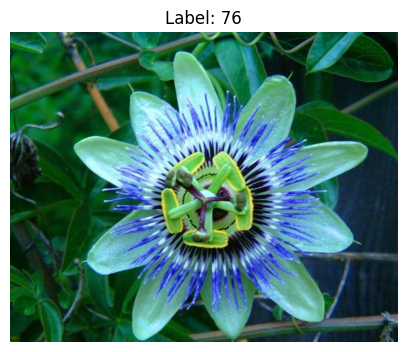

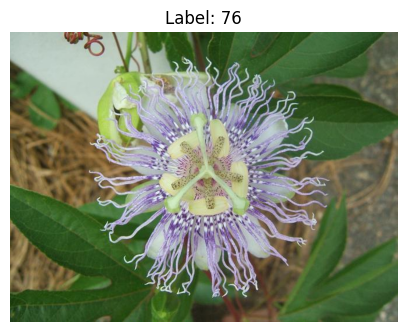

In [39]:
# Select the index of a known corrupted image (image 2, using zero-based indexing).
idx = 1

# Retrieve the sample; the dataset should log the error and try the next image.
img, label = robust_dataset[idx]

# Display the image returned by the dataset.
helper_utils.plot_img(img, label=label)

# Retrieve the following sample directly for comparison.
next_img, next_label = robust_dataset[idx + 1]

# Display the next sample to compare the results.
helper_utils.plot_img(next_img, label=next_label)

In [40]:
# Select the index of the image stored in grayscale (image 5).
idx = 4

# Build the path to the original image file.
original_img_path = os.path.join(
    robust_dataset.img_dir,
    f"image_{idx + 1:05d}.jpg"
)

# Open the image and inspect its original color mode.
with Image.open(original_img_path) as original_img:
    print(f"Original image mode: {original_img.mode}")

# 'L' indicates grayscale; 'RGB' indicates a three-channel color image.

Original image mode: L


Corrected image mode: RGB


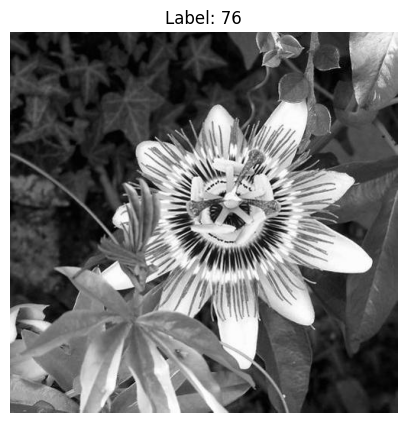

In [41]:
# Retrieve the image; the dataset converts it to RGB during loading.
img, label = robust_dataset[idx]

# Display the image after the color-mode conversion.
helper_utils.plot_img(img, label=label)

# Confirm that the loaded image uses RGB color mode.
print(f"Corrected image mode: {img.mode}")

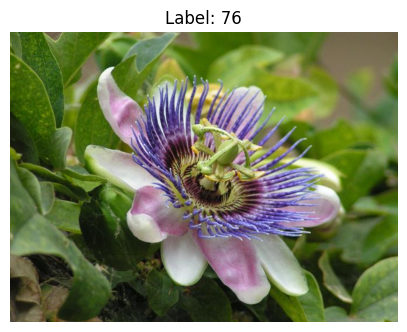

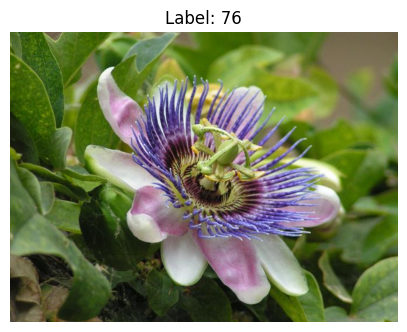

In [42]:
# Select the index of a known corrupted or unreadable image.
idx = 6

# Retrieve the sample; the dataset should log the error and try the next image.
robust_img, robust_label = robust_dataset[idx]

# Display the image returned by the fallback logic.
helper_utils.plot_img(robust_img, label=robust_label)

# Retrieve the next sample directly for comparison.
next_img, next_label = robust_dataset[idx + 1]

# Display the next image to check whether the fallback returned that sample.
helper_utils.plot_img(next_img, label=next_label)

The tests cover three images with different issues:

- **Image 2** — Too small to meet the minimum image-size requirement.
- **Image 4** — Grayscale; converted to RGB automatically, so this does not necessarily generate an error.
- **Image 6** — Corrupted or unreadable; expected to trigger an error during image loading.

The errors are recorded in `robust_dataset.error_logs`. You can review them using `robust_dataset.get_error_summary()`.

**Note:** Only images that raise exceptions are logged. Image 4's grayscale conversion is handled normally, without an error, unless another issue occurs while loading it.

In [43]:
# Display the summary of any corrupted or problematic images found during loading.
robust_dataset.get_error_summary()


Encountered 2 loading errors:
  Index 2: Image too small: (20, 20)
  Index 6: cannot identify image file '/content/ML-engineering-portfolio/projects/02-FlowerFlow/corrupted_flower_data/jpg/image_00007.jpg'


## Tracking Dataset Errors and Performance

A reliable data pipeline needs to handle corrupted files and make it easier to identify issues that could affect data loading and model development.

In this section, I'll extend `RobustFlowerDataset` with a `MonitoredDataset` class to track dataset access, measure image loading times, and summarize potential issues.

### Monitoring Features

The `MonitoredDataset` class adds three key capabilities:

- **Access tracking** — Records how often each image index is requested through `__getitem__`, helping identify frequently accessed and unused samples.
- **Load-time measurement** — Tracks image retrieval time and prints a warning when loading an image takes longer than one second. This helps identify potential data-loading bottlenecks.
- **Statistics reporting** — Provides a `print_stats()` method that reports:
  - Total number of images in the dataset.
  - Number of unique images accessed.
  - Number of errors recorded by the parent class.
  - Average and maximum image loading times.
  - A warning if some images have not been accessed, with examples of the affected indices.

These monitoring features make dataset behavior more transparent and help identify data quality issues and potential performance bottlenecks during development.

**Note:** Access counts and loading times are diagnostic measurements, not proof that the dataset is production-ready. They should be interpreted alongside validation checks and the actual behavior of the training pipeline.

In [44]:
class MonitoredDataset(RobustFlowerDataset):
    """
    Extend RobustFlowerDataset with access tracking and performance monitoring.

    Tracks how often each sample is requested, measures loading time, and
    reports dataset usage and error statistics.
    """

    def __init__(self, *args, **kwargs):
        """Initialize the parent dataset and monitoring attributes."""
        # Initialize the robust dataset with the provided arguments.
        super().__init__(*args, **kwargs)

        # Track the number of times each dataset index is accessed.
        self.access_counts = {}

        # Store the loading time recorded for each access.
        self.load_times = []

    def __getitem__(self, idx):
        """Retrieve a sample while recording access counts and loading time."""
        # Import time locally to measure how long sample retrieval takes.
        import time

        # Record the start time and update the access count.
        start_time = time.time()
        self.access_counts[idx] = self.access_counts.get(idx, 0) + 1

        # Retrieve the sample using the parent's error-handling logic.
        result = super().__getitem__(idx)

        # Record the elapsed time for this retrieval.
        load_time = time.time() - start_time
        self.load_times.append(load_time)

        # Flag sample retrievals that exceed the one-second threshold.
        if load_time > 1.0:
            print(f"⚠️ Slow load: Image {idx} took {load_time:.2f}s")

        return result

    def print_stats(self):
        """Print dataset usage, error, and loading-time statistics."""
        # Summarize dataset access and any errors recorded.
        print("\n=== Pipeline Statistics ===")
        print(f"Total images: {len(self)}")
        print(f"Unique images accessed: {len(self.access_counts)}")
        print(f"Errors encountered: {len(self.error_logs)}")

        # Report loading-time statistics when samples have been retrieved.
        if self.load_times:
            avg_time = sum(self.load_times) / len(self.load_times)
            max_time = max(self.load_times)

            print(f"Average load time: {avg_time * 1000:.1f} ms")
            print(f"Slowest load: {max_time * 1000:.1f} ms")

        # Compare all dataset indices with those accessed so far.
        all_indices = set(range(len(self)))
        accessed_indices = set(self.access_counts.keys())
        never_accessed = all_indices - accessed_indices

        # Report samples that have not been accessed.
        if never_accessed:
            print(
                f"\n⚠️ WARNING: {len(never_accessed)} images were never loaded!"
            )
            print(f"   Examples: {list(never_accessed)[:5]}")

In [ ]:
# Initialize the monitored dataset using the path to the potentially corrupted images.
monitored_dataset = MonitoredDataset(corrupted_dataset_path)

# Iterate through every dataset index to simulate a complete pass over the data.
for idx in range(len(monitored_dataset)):
    # Retrieve each sample to record access counts, measure loading time,
    # and trigger the inherited error-handling logic when needed.
    img, label = monitored_dataset[idx]

Streaming output truncated to the last 5000 lines.


In [ ]:
# Print the statistics
monitored_dataset.print_stats()

The `print_stats()` method summarizes dataset usage, loading performance, and errors encountered during data retrieval.

Including this type of monitoring in a dataset class makes it easier to identify problematic samples, track data access, and spot potential loading bottlenecks. These insights help me assess data quality and improve the reliability of the data pipeline.

## Conclusion

In this project, I built a reusable PyTorch data pipeline for loading, preprocessing, and managing the Oxford Flowers 102 dataset.

The workflow covered several key aspects of data management:

- **Custom dataset implementation** — Created a `FlowerDataset` class to load images and their corresponding labels on demand.
- **Image preprocessing** — Applied resizing, cropping, tensor conversion, and normalization to standardize the input images.
- **Data augmentation** — Introduced random transformations to create varied versions of training images.
- **Dataset splitting and batching** — Organized the data into training, validation, and test subsets and used `DataLoader` to manage batching and shuffling.
- **Error handling** — Extended the dataset implementation to validate images, handle loading failures, and record errors.
- **Performance monitoring** — Added access tracking and loading-time measurements to help identify potential data pipeline issues.

This project strengthened my understanding of how to build data pipelines that are organized, reusable, and better equipped to handle imperfect data.

The result is a solid foundation for the next stages of an ML workflow, where reliable data loading and preprocessing support model development and evaluation.